# Advanced Machine Learning (CS60073)
## **Assignment 3:** Generative modeling (Total Marks: 100)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

RANDOM_SEED = 1234
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
device = torch.device("cpu")

## Part B – Tiny Image Diffusion Model (40 marks)

**Goal:** Implement a denoising diffusion probabilistic model (DDPM) on a small subset of
`MNIST`. Understand the forward diffusion process, learn to predict noise, implement reverse
sampling, and investigate classifier-free guidance for class-conditioned generation.

**Dataset and Settings**
Use the MNIST dataset from `torchvision`. Retain only digits 0 and 1, selecting the first
1,000 training images of each class. Use the first 200 test images of each class for evaluation.
Normalize images from [0, 1] to [−1, 1].
Use the following settings throughout:
- Image size: 28 × 28 grayscale.
- Diffusion steps: T = 20.
- Noise schedule: linearly spaced βt from 0.0001 to 0.02.
- Optimizer: `Adam`, learning rate 1e−3.
- Batch size: 64; epochs: 5.
- Random seed: 1234; CPU only.

### (a) Fixed Settings

The assignment settings are defined as constants for consistent use throughout the notebook.

In [2]:
IMAGE_SIZE = 28
T = 20
BATCH_SIZE = 64
EPOCHS = 5
LEARNING_RATE = 1e-3
NUM_TRAIN_PER_CLASS = 1000
NUM_TEST_PER_CLASS = 200
NUM_CLASSES = 2

### (b) Load and Prepare the MNIST Dataset

The MNIST training and test datasets are loaded using `torchvision`. Only the first 1,000 training images and the first 200 test images belonging to each of the digit classes 0 and 1 are retained. The pixel values are normalized from \($[0,1]$\) to \($[-1,1]$\), and the images and corresponding labels are stored in tensors. Data loaders are created to facilitate batch-wise processing.

In [3]:
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms

# Convert images to tensors and normalize [0, 1] to [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Download/load MNIST
train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

def select_digits(dataset, samples_per_class):
    images_by_class = {0: [], 1: []}

    for image, label in dataset:
        if label in images_by_class and len(images_by_class[label]) < samples_per_class:
            images_by_class[label].append(image)

        if all(len(images_by_class[c]) == samples_per_class for c in [0, 1]):
            break

    images = torch.stack(images_by_class[0] + images_by_class[1])
    labels = torch.tensor(
        [0] * samples_per_class + [1] * samples_per_class,
        dtype=torch.long
    )
    return images, labels

# Select the required subsets
x_train, y_train = select_digits(train_dataset, NUM_TRAIN_PER_CLASS)
x_test, y_test = select_digits(test_dataset, NUM_TEST_PER_CLASS)

# Create data loaders
train_loader = DataLoader(
    TensorDataset(x_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(RANDOM_SEED)
)

test_loader = DataLoader(
    TensorDataset(x_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)
print("Training pixel range:", x_train.min().item(), x_train.max().item())
print("Training class counts:", torch.bincount(y_train).tolist())
print("Test class counts:", torch.bincount(y_test).tolist())

Training images: torch.Size([2000, 1, 28, 28])
Training labels: torch.Size([2000])
Test images: torch.Size([400, 1, 28, 28])
Test labels: torch.Size([400])
Training pixel range: -1.0 1.0
Training class counts: [1000, 1000]
Test class counts: [200, 200]


## 1) Dataset and Forward Diffusion (8 marks)

### (a) Load the specified subset of MNIST and display a grid containing five images from each class. Report the number of training and test images. (2 marks)

Number of training images: 2000
Number of test images: 400
Training images per class: [1000, 1000]
Test images per class: [200, 200]


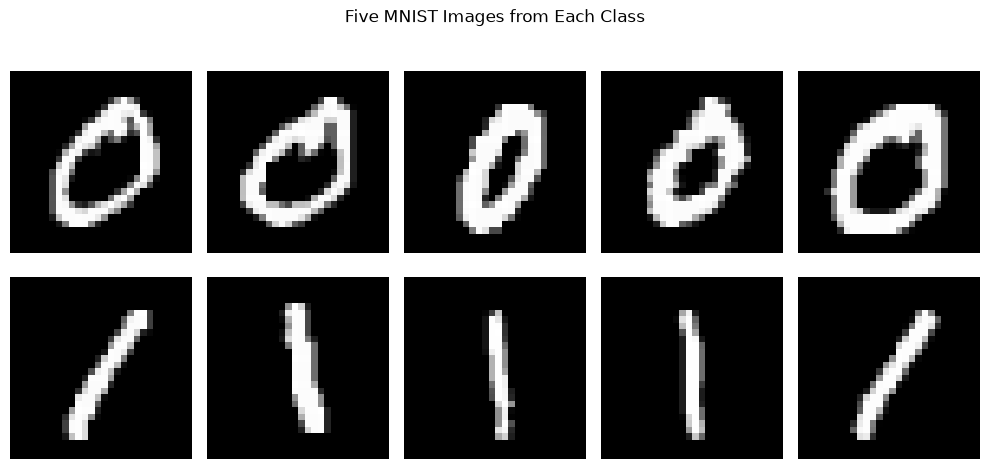

In [4]:
# Display five training images from each class
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for digit in [0, 1]:
    digit_indices = torch.where(y_train == digit)[0][:5]

    for j, idx in enumerate(digit_indices):
        image = (x_train[idx, 0] + 1) / 2
        axes[digit, j].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[digit, j].axis("off")

        if j == 0:
            axes[digit, j].set_ylabel(f"Digit {digit}")

plt.suptitle("Five MNIST Images from Each Class")
plt.tight_layout()

# Report dataset sizes
print("Number of training images:", len(x_train))
print("Number of test images:", len(x_test))
print("Training images per class:", torch.bincount(y_train).tolist())
print("Test images per class:", torch.bincount(y_test).tolist())

### (b) Calculate \($\alpha_t = 1 - \beta_t$\) and \($\bar{\alpha}_t = \prod_{s=1}^{t}\alpha_s$\). Implement the forward diffusion process using

$$
q(x_t \mid x_0) =
\mathcal{N}\left(
\sqrt{\bar{\alpha}_t}x_0,\,
(1-\bar{\alpha}_t)I
\right),
$$
**or equivalently,**
$$
x_t =
\sqrt{\bar{\alpha}_t}x_0
+
\sqrt{1-\bar{\alpha}_t}\epsilon,
\qquad
\epsilon \sim \mathcal{N}(0,I).
$$
**(3 marks)**

In [5]:
# Define the noise schedule
betas = torch.linspace(0.0001, 0.02, T, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

# Print the calculated noise schedule
print("Betas:", betas.cpu().numpy())
print("Alphas:", alphas.cpu().numpy())
print("Cumulative alpha bars:", alpha_bars.cpu().numpy())

def extract(values, timesteps, x_shape):
    # Extract timestep-specific values and reshape for broadcasting
    extracted = values[timesteps]
    return extracted.reshape(timesteps.shape[0], *([1] * (len(x_shape) - 1)))

def forward_diffusion(x_0, timesteps, noise=None):
    # Generate Gaussian noise when it is not supplied
    if noise is None:
        noise = torch.randn_like(x_0)

    # Extract cumulative alpha values for the selected timesteps
    alpha_bar_t = extract(alpha_bars, timesteps, x_0.shape)

    # Generate the noisy images using the closed-form equation
    x_t = torch.sqrt(alpha_bar_t) * x_0 + torch.sqrt(1.0 - alpha_bar_t) * noise

    return x_t, noise

Betas: [0.0001     0.00114737 0.00219474 0.00324211 0.00428947 0.00533684
 0.00638421 0.00743158 0.00847895 0.00952632 0.01057368 0.01162105
 0.01266842 0.01371579 0.01476316 0.01581053 0.01685789 0.01790526
 0.01895263 0.02      ]
Alphas: [0.9999     0.9988526  0.99780524 0.99675786 0.99571055 0.9946632
 0.9936158  0.99256843 0.99152106 0.9904737  0.9894263  0.98837894
 0.98733157 0.9862842  0.9852368  0.98418945 0.9831421  0.98209476
 0.9810474  0.98      ]
Cumulative alpha bars: [0.9999     0.9987527  0.9965607  0.9933297  0.98906887 0.9837904
 0.9775097  0.97024524 0.9620186  0.9528541  0.94277894 0.93182284
 0.9200181  0.9073993  0.8940032  0.8798685  0.8650358  0.8495471
 0.83344597 0.81677705]


### (c) For one test image, use a fixed noise realization to generate $x_t$ at t ∈ {1, 5, 10, 20}. Display the original image and the four noisy images. Explain how the image changes as t increases. (3 marks)

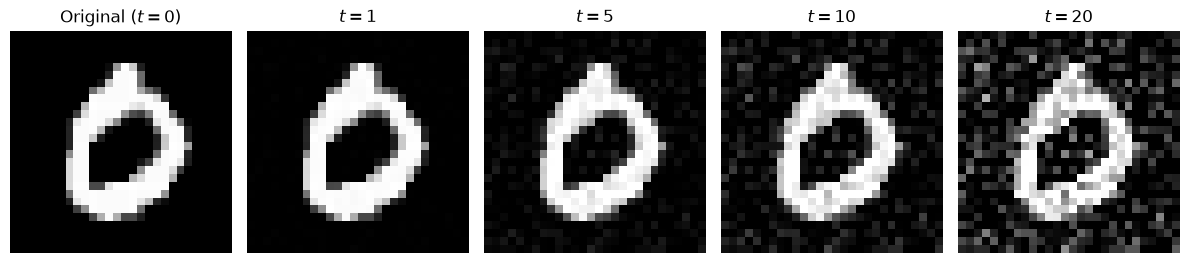

In [6]:
# Select one test image and generate a fixed noise realization
x_0 = x_test[0:1].to(device)
fixed_noise = torch.randn_like(x_0)

# Define the requested timesteps using one-based indexing
timesteps_to_show = [1, 5, 10, 20]
noisy_images = []

# Generate noisy images using the same noise realization
for t in timesteps_to_show:
    timestep = torch.tensor([t - 1], device=device)
    x_t, _ = forward_diffusion(x_0, timestep, noise=fixed_noise)
    noisy_images.append(x_t[0, 0].cpu())

# Display the original image and the four noisy images
fig, axes = plt.subplots(1, 5, figsize=(12, 3))

axes[0].imshow(((x_0[0, 0].cpu() + 1) / 2), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original ($t=0$)")
axes[0].axis("off")

for i, t in enumerate(timesteps_to_show):
    image = (noisy_images[i] + 1) / 2
    axes[i + 1].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[i + 1].set_title(f"$t={t}$")
    axes[i + 1].axis("off")

plt.tight_layout()

**Observation:** As \($t$\) increases, the image becomes **progressively noisier**, and the digit structure becomes less distinguishable. This occurs because the contribution of the original image decreases while the Gaussian noise contribution increases.

## 2) Noise Prediction Network and Training (10 marks)

Implement a small convolutional noise-prediction network \($\epsilon_\theta(x_t, t, c)$\), where \(c\) is the class condition.

Use the following architecture:

- Input: three channels consisting of the noisy image, a spatially broadcast timestep \($t/T$\), and a spatially broadcast class condition.
- Conv2d(3 → 32, 3) + ReLU.
- Conv2d(32 → 64, 3) + ReLU.
- Conv2d(64 → 32, 3) + ReLU.
- Conv2d(32 → 1, 3).

Use padding 1 for every convolution to preserve image dimensions. Represent classes 0 and 1 by their respective numeric labels, and use \($c = -1$\) as the null condition.

Train the network using the noise-prediction objective

$$
L_{\text{simple}} =
\mathbb{E}_{x_0,t,\epsilon,c}
\left[
\left\|\epsilon-\epsilon_\theta(x_t,t,c)\right\|_2^2
\right].
$$

At each training iteration, sample \(t\) uniformly from \(${1,\ldots,T}$\) and \($\epsilon \sim \mathcal{N}(0,I)$\). Independently replace the class condition with \($c = -1$\) with probability \(0.2\) to enable classifier-free guidance.

### (a) Implement the network and verify that its output has dimensions B × 1 × 28 × 28. (3 marks)

In [7]:
class NoisePredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 1, kernel_size=3, padding=1)
        )

    def forward(self, x_t, t, c):
        batch_size, _, height, width = x_t.shape

        # Normalize and spatially broadcast the timestep
        t_channel = (t.float() / T).view(batch_size, 1, 1, 1)
        t_channel = t_channel.expand(batch_size, 1, height, width)

        # Spatially broadcast the class condition
        c_channel = c.float().view(batch_size, 1, 1, 1)
        c_channel = c_channel.expand(batch_size, 1, height, width)

        # Combine the three input channels
        network_input = torch.cat([x_t, t_channel, c_channel], dim=1)

        return self.network(network_input)

# Initialize the network and verify the output dimensions
model = NoisePredictor().to(device)

sample_x_t = torch.randn(BATCH_SIZE, 1, 28, 28, device=device)
sample_t = torch.randint(1, T + 1, (BATCH_SIZE,), device=device)
sample_c = torch.arange(BATCH_SIZE, device=device) % NUM_CLASSES

with torch.no_grad():
    sample_output = model(sample_x_t, sample_t, sample_c)

print("Input shape:", sample_x_t.shape)
print("Output shape:", sample_output.shape)
print("Expected shape:", (BATCH_SIZE, 1, 28, 28))

assert sample_output.shape == (BATCH_SIZE, 1, 28, 28)
print("Output dimensions verified successfully.")

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 1, 28, 28])
Expected shape: (64, 1, 28, 28)
Output dimensions verified successfully.


### (b) Implement the training loop and train for five epochs. Plot the training loss against epochs. (4 marks)

Epoch [1/5], Loss: 0.697899
Epoch [2/5], Loss: 0.397000
Epoch [3/5], Loss: 0.279520
Epoch [4/5], Loss: 0.223373
Epoch [5/5], Loss: 0.202184


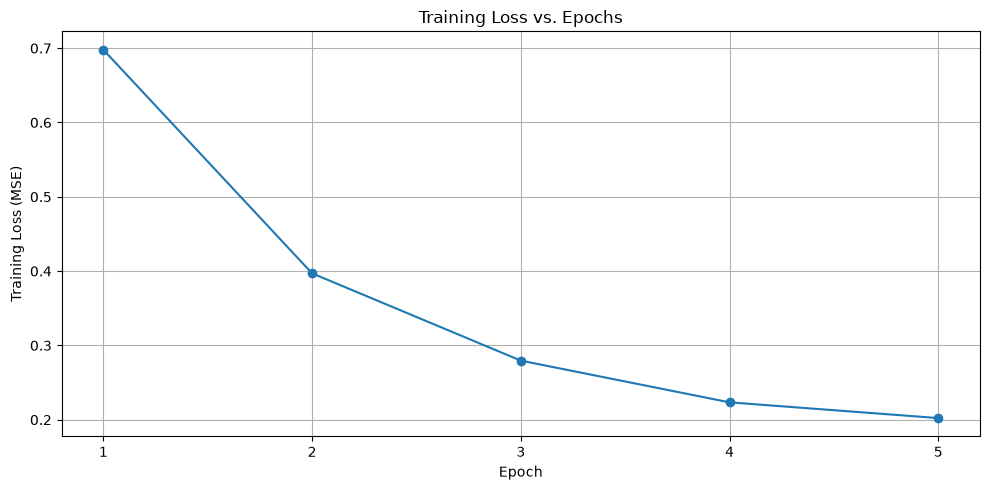

In [8]:
CLASS_DROP_PROB = 0.2

# Initialize the optimizer and loss function
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.MSELoss()
training_losses = []

# Train the network for five epochs
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for x_0, labels in train_loader:
        x_0 = x_0.to(device)
        labels = labels.to(device)
        batch_size = x_0.shape[0]

        # Sample timesteps and Gaussian noise
        timesteps = torch.randint(1, T + 1, (batch_size,), device=device)
        x_t, noise = forward_diffusion(x_0, timesteps - 1)

        # Independently drop class conditions with probability 0.2
        drop_mask = torch.rand(batch_size, device=device) < CLASS_DROP_PROB
        conditions = labels.clone()
        conditions[drop_mask] = -1

        # Predict the added noise
        predicted_noise = model(x_t, timesteps, conditions)

        # Calculate the noise-prediction loss
        loss = criterion(predicted_noise, noise)

        # Update network parameters
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_size

    # Record and report the average epoch loss
    epoch_loss = running_loss / len(train_loader.dataset)
    training_losses.append(epoch_loss)
    print(f"Epoch [{epoch + 1}/{EPOCHS}], Loss: {epoch_loss:.6f}")

# Plot training loss against epochs
plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS + 1), training_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss (MSE)")
plt.title("Training Loss vs. Epochs")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True)
plt.tight_layout()

### (c) Explain why the training target is the sampled noise $\epsilon$\, rather than the clean image $x_0$. Explain the purpose of randomly dropping the class condition. (3 marks)

**Why is the sampled noise \($\epsilon$\) used as the training target?**

The sampled noise \($\epsilon$\) is used as the training target because the **diffusion model is trained to reverse the noise added during the forward diffusion process**. By predicting the noise, the model can progressively remove it from noisy images during generation and recover clean images.

**Purpose of randomly dropping the class condition:**

The class condition is randomly replaced with \(c=-1\) with probability \(0.2\) to enable **classifier-free guidance**. This allows the network to learn both conditional and unconditional noise predictions, which can be combined during generation to control how strongly the generated images match the desired class.

## 3) Reverse Diffusion Without Guidance (8 marks)

### (a) Implement the complete reverse diffusion loop and generate 25 images using unconditional sampling. (4 marks)

In [9]:
# Implement reverse diffusion without class guidance
@torch.no_grad()
def sample_unconditional(num_images=25):
    model.eval()

    # Initialize images from Gaussian noise
    x_t = torch.randn(num_images, 1, 28, 28, device=device)

    # Use the null class condition for unconditional sampling
    conditions = torch.full((num_images,), -1, device=device)

    # Iteratively remove noise from timestep T to 1
    for t in range(T, 0, -1):
        timesteps = torch.full((num_images,), t, device=device, dtype=torch.long)

        # Predict the noise at the current timestep
        predicted_noise = model(x_t, timesteps, conditions)

        # Retrieve schedule values using zero-based indexing
        beta_t = betas[t - 1]
        alpha_t = alphas[t - 1]
        alpha_bar_t = alpha_bars[t - 1]

        # Calculate the reverse diffusion mean
        mean = (x_t - (beta_t / torch.sqrt(1 - alpha_bar_t)) * predicted_noise) / torch.sqrt(alpha_t)
        
        # Calculate the posterior variance for the reverse step
        alpha_bar_prev = alpha_bars[t - 2] if t > 1 else torch.tensor(1.0, device=device)
        posterior_variance = beta_t * (1 - alpha_bar_prev) / (1 - alpha_bar_t)

        # Add noise except at the final reverse step
        if t > 1:
            noise = torch.randn_like(x_t)
            x_t = mean + torch.sqrt(posterior_variance) * noise
        else:
            x_t = mean

    # Convert generated images to the range [0, 1]
    return ((x_t.clamp(-1, 1) + 1) / 2).cpu()

# Generate 25 unconditional samples
generated_images = sample_unconditional(num_images=25)
print("Generated images shape:", generated_images.shape)

Generated images shape: torch.Size([25, 1, 28, 28])


### (b) Display the generated images in a 5 × 5 grid. Explain how the reverse process approximately inverts the forward noising process. (2 marks)

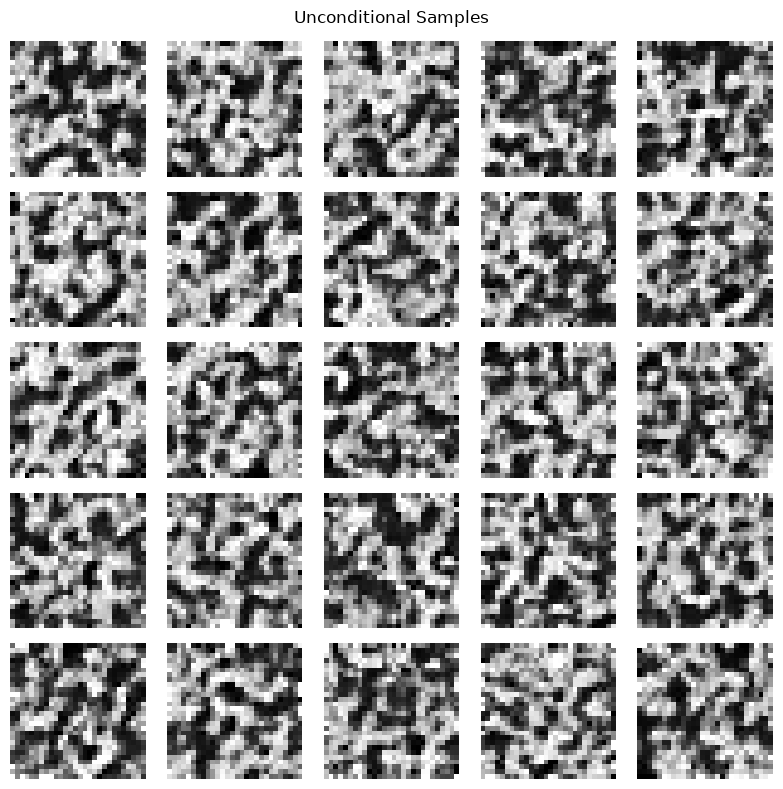

In [10]:
# Display generated images in a 5x5 grid
fig, axes = plt.subplots(5, 5, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_images[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.suptitle("Unconditional Samples")
plt.tight_layout()

**Explanation** 

The forward process gradually adds Gaussian noise to clean images, whereas the reverse process uses predicted noise to progressively remove it. This approximately reconstructs the image distribution. Imperfect noise predictions and limited training may result in unclear or noisy generated images.

### (c) Identify the role of the predicted noise, reverse-process variance, and initial Gaussian noise in the sampling algorithm. (2 marks)

**Role of each component**

- **Predicted noise:** Estimates the Gaussian noise present in the current image, which is used to progressively remove noise during reverse diffusion.
- **Reverse-process variance:** Controls the amount of random noise added at each reverse step, maintaining the stochastic nature of sampling.
- **Initial Gaussian noise:** Provides a random starting point from which the image is gradually generated through the reverse diffusion process.

## 4) Classifier-Free Guidance (8 marks)

Implement class-conditioned generation using classifier-free guidance. For a requested class
\($c \in \{0, 1$\}\), compute

$$
\epsilon_{\text{guided}} = \epsilon_\theta(x_t, t, -1) + w \left[\epsilon_\theta(x_t, t, c) - \epsilon_\theta(x_t, t, -1)\right].
$$

Use \(w = 2\) initially. Substitute \($\epsilon_{\text{guided}}$\) into the reverse-process mean equation from Question 3
and use the same reverse variance.

### (a) Implement guided sampling and generate 25 images for each class. Display the results in two separate 5 × 5 grids. (3 marks)

Class 0 samples shape: torch.Size([25, 1, 28, 28])
Class 1 samples shape: torch.Size([25, 1, 28, 28])


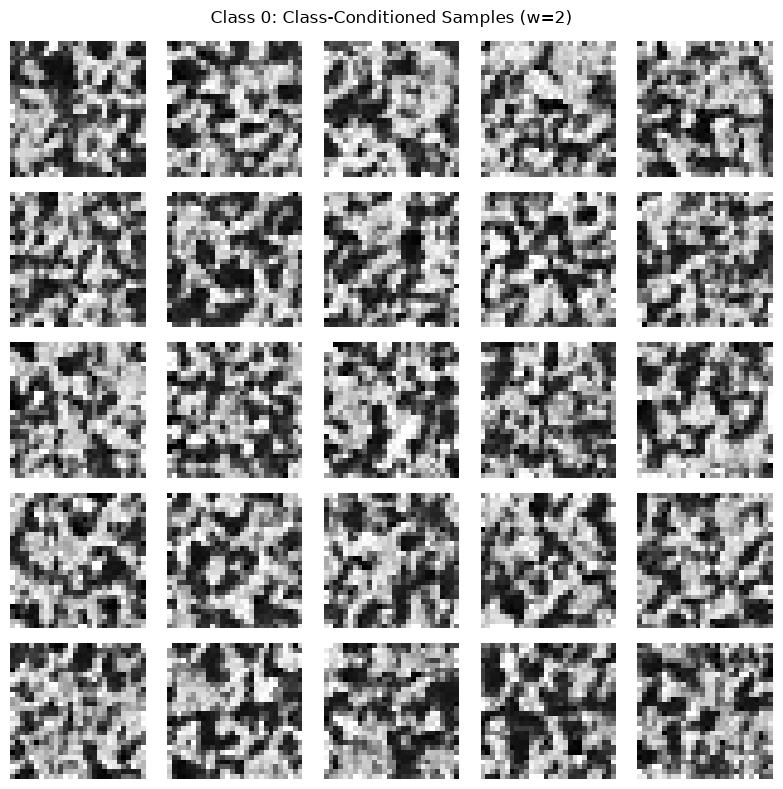

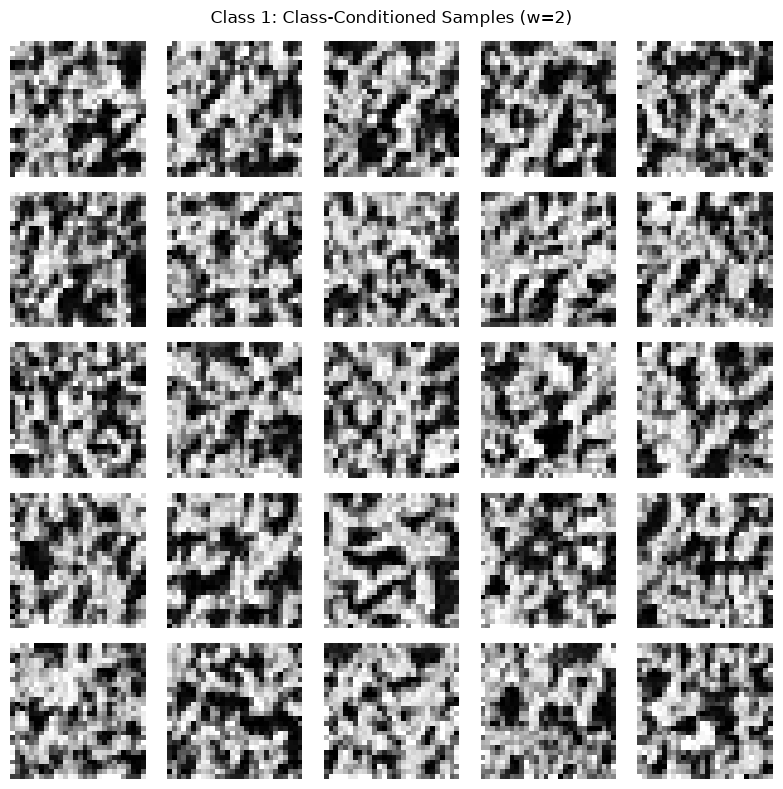

In [14]:
# Implement classifier-free guided sampling
@torch.no_grad()
def sample_guided(class_label, num_images=25, guidance_scale=2.0):
    model.eval()

    # Initialize images from Gaussian noise
    x_t = torch.randn(num_images, 1, 28, 28, device=device)

    # Define unconditional and class-conditional labels
    conditions_uncond = torch.full((num_images,), -1, device=device)
    conditions_cond = torch.full((num_images,), class_label, device=device)

    # Iteratively reverse the diffusion process
    for t in range(T, 0, -1):
        timesteps = torch.full((num_images,), t, device=device, dtype=torch.long)

        # Predict noise without and with class conditioning
        noise_uncond = model(x_t, timesteps, conditions_uncond)
        noise_cond = model(x_t, timesteps, conditions_cond)

        # Apply classifier-free guidance
        guided_noise = noise_uncond + guidance_scale * (noise_cond - noise_uncond)

        # Retrieve schedule values
        beta_t = betas[t - 1]
        alpha_t = alphas[t - 1]
        alpha_bar_t = alpha_bars[t - 1]

        # Calculate the reverse diffusion mean
        mean = (x_t - (beta_t / torch.sqrt(1 - alpha_bar_t)) * guided_noise) / torch.sqrt(alpha_t)

        # Calculate the posterior variance, matching Question 3
        alpha_bar_prev = alpha_bars[t - 2] if t > 1 else torch.tensor(1.0, device=device)
        posterior_variance = beta_t * (1 - alpha_bar_prev) / (1 - alpha_bar_t)

        # Add noise except at the final reverse step
        if t > 1:
            x_t = mean + torch.sqrt(posterior_variance) * torch.randn_like(x_t)
        else:
            x_t = mean

    # Convert generated images to [0, 1]
    return ((x_t.clamp(-1, 1) + 1) / 2).cpu()

# Generate 25 images for each class
samples_class_0 = sample_guided(class_label=0, num_images=25, guidance_scale=2.0)
samples_class_1 = sample_guided(class_label=1, num_images=25, guidance_scale=2.0)

print("Class 0 samples shape:", samples_class_0.shape)
print("Class 1 samples shape:", samples_class_1.shape)

# Display the generated images in separate 5 x 5 grids
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples_class_0[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Class 0: Class-Conditioned Samples (w=2)")
plt.tight_layout()

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples_class_1[i, 0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Class 1: Class-Conditioned Samples (w=2)")
plt.tight_layout()

### (b) Generate images for both classes using guidance scales w ∈ {0, 1, 2}. Display the results and compare the effect of guidance on class-specific generation. (3 marks)

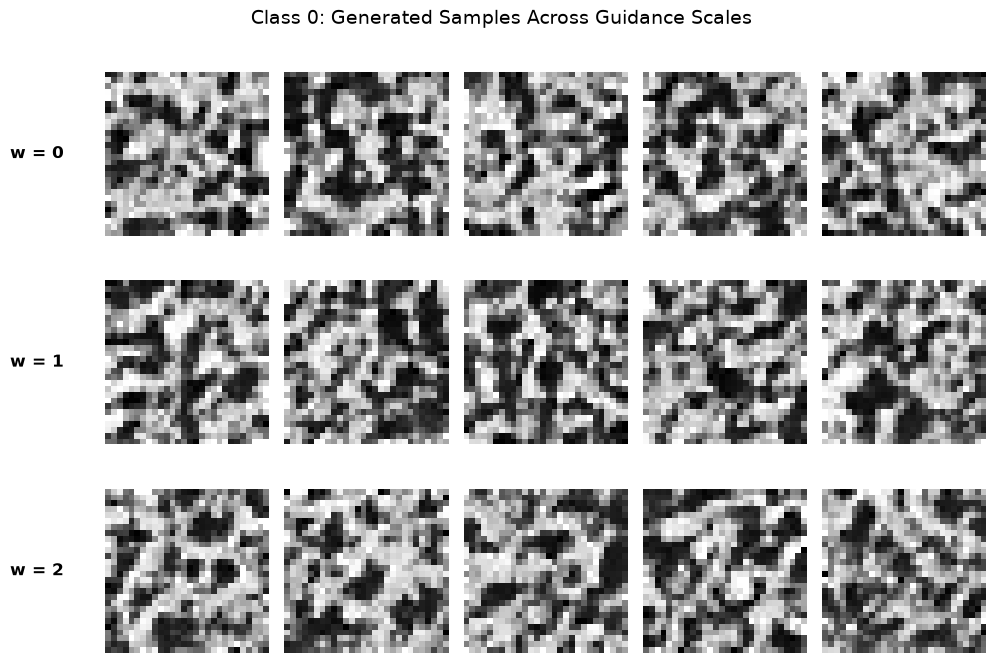

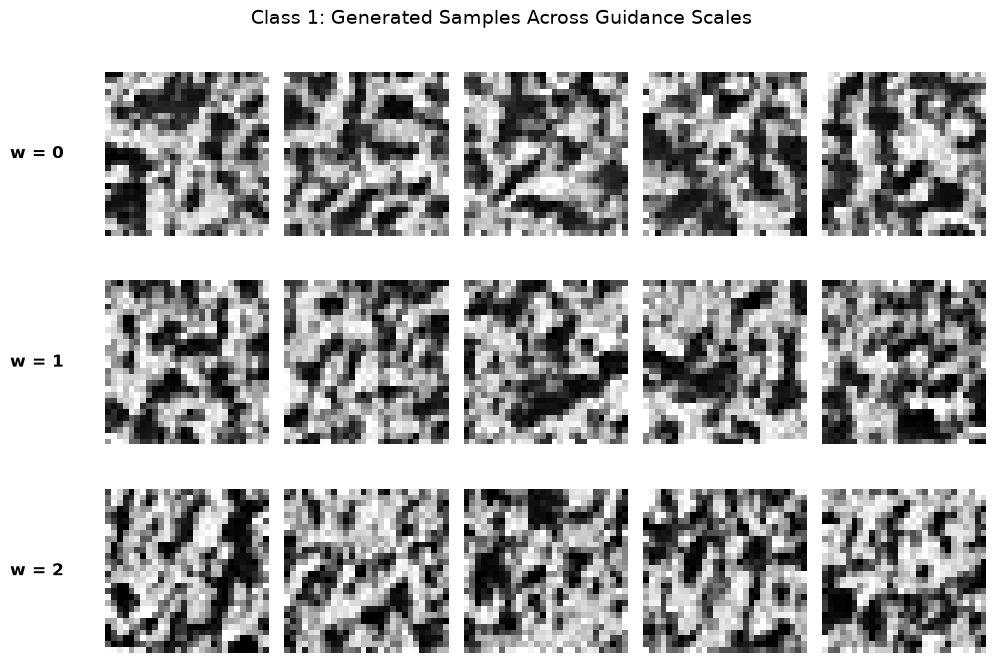

In [15]:
# Generate samples for both classes using different guidance scales
guidance_scales = [0, 1, 2]
class_labels = [0, 1]
num_images = 25
generated_samples = {}

for class_label in class_labels:
    for guidance_scale in guidance_scales:
        generated_samples[(class_label, guidance_scale)] = sample_guided(
            class_label=class_label,
            num_images=num_images,
            guidance_scale=guidance_scale
        )

# Display results in separate grids for each class
for class_label in class_labels:
    fig, axes = plt.subplots(3, 5, figsize=(10, 7))

    for row, guidance_scale in enumerate(guidance_scales):
        for col, ax in enumerate(axes[row]):
            samples = generated_samples[(class_label, guidance_scale)]
            ax.imshow(samples[col, 0], cmap="gray", vmin=0, vmax=1)
            ax.axis("off")

        # Display the guidance scale beside each row
        axes[row, 0].text(
            -0.25, 0.5, f"w = {guidance_scale}",
            transform=axes[row, 0].transAxes,
            ha="right", va="center",
            fontsize=12, fontweight="bold",
            clip_on=False
        )

    fig.suptitle(
        f"Class {class_label}: Generated Samples Across Guidance Scales",
        fontsize=14
    )
    fig.subplots_adjust(left=0.18, top=0.88, hspace=0.15, wspace=0.05)
    plt.tight_layout()

**Observation** 

The generated images remain largely noisy and unrecognizable across guidance scales \($w \in \{0,1,2$\}\), with no clear improvement in class-specific generation as the guidance scale increases. This may be attributed to the limited training of five epochs and the short diffusion schedule of \(T=20\), whose final forward distribution remains far from pure Gaussian noise. Thus, increasing the guidance scale does not noticeably improve generation quality under the prescribed settings.

### (c) Explain what w = 0 and w = 1 represent, and why a larger guidance scale does not necessarily produce better images. (2 marks)

**Explanation** 

- At \(w=0\), the unconditional noise prediction is used, so no explicit class guidance is applied. 
- At \(w=1\), the conditional noise prediction is used directly, providing class-specific guidance. 
- A larger guidance scale strengthens the influence of the requested class but may also amplify prediction errors, reduce image diversity, and introduce artifacts. Therefore, stronger guidance does not necessarily produce better images, particularly when training is limited and the diffusion schedule is short.

## 5) Evaluation and Discussion (6 marks)

### (a) Compare unconditional and guided generation by inspecting the generated image grids. Discuss class consistency, image quality, and diversity. (2 marks)

**Observation** 

Both the unconditional and class-guided samples remain largely noisy and unrecognizable. Unconditional generation does not target a specific digit class, whereas guided generation is intended to produce images resembling the requested class, 0 or 1. However, clear class consistency is not observed in the generated grids. Image quality remains poor in both cases, and diversity cannot be reliably assessed because recognizable digit structures are largely absent. This may be due to the limited training of five epochs and the short diffusion schedule of \(T=20\), which restrict the model's ability to learn effective denoising.

### (b) Report the mean squared noise-prediction error on the held-out test subset. Evaluate the model at several diffusion timesteps using fresh Gaussian noise. (2 marks)

In [16]:
# Evaluate noise-prediction error on the test subset
model.eval()
test_timesteps = [1, 5, 10, 15, 20]

with torch.no_grad():
    for t in test_timesteps:
        timesteps = torch.full((len(x_test),), t, device=device, dtype=torch.long)
        noise = torch.randn_like(x_test)
        x_t, noise = forward_diffusion(x_test, timesteps - 1, noise)
        conditions = y_test.to(device)
        predicted_noise = model(x_t, timesteps, conditions)
        mse = torch.mean((predicted_noise - noise) ** 2).item()
        print(f"Timestep {t:2d}: Test noise-prediction MSE = {mse:.6f}")

Timestep  1: Test noise-prediction MSE = 0.801139
Timestep  5: Test noise-prediction MSE = 0.186802
Timestep 10: Test noise-prediction MSE = 0.120761
Timestep 15: Test noise-prediction MSE = 0.098979
Timestep 20: Test noise-prediction MSE = 0.093191


**Observation** 

The test noise-prediction MSE decreased from timestep \(t=1\) to \(t=20\). This indicates that noise prediction was more accurate at later diffusion timesteps and less accurate at earlier timesteps. Overall, the model's prediction accuracy varied with the noise level, demonstrating that denoising performance depends on the diffusion timestep.

### (c) Discuss two limitations of training a diffusion model on a small dataset for only five epochs. Suggest one improvement to the model or training procedure. (2 marks)

**Limitations** 

- The small training dataset limits the diversity of examples, reducing the model's ability to learn robust representations of digit variations and potentially leading to poor image quality. 
- Training for only five epochs may result in underfitting, as the model may not learn an accurate noise-prediction function, producing noisy and unrecognizable samples.

**Improvement** 
Training for more epochs on a larger dataset containing more classes would allow the model to learn more robust denoising patterns and generate clearer, more diverse, and more class-consistent images.

---
End of the assignment